In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

In [2]:
# Load Diabetes dataset
X, y = load_diabetes(return_X_y=True)

# Use only ONE feature to make double descent very clear
X = X[:, np.newaxis, 2]  # BMI feature

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])


Train samples: 309
Test samples: 133


In [3]:
degrees = range(1, 40)

train_errors = []
test_errors = []

for d in degrees:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=d, include_bias=False)),
        ("lr", LinearRegression())
    ])

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_errors.append(mean_squared_error(y_train, y_train_pred))
    test_errors.append(mean_squared_error(y_test, y_test_pred))


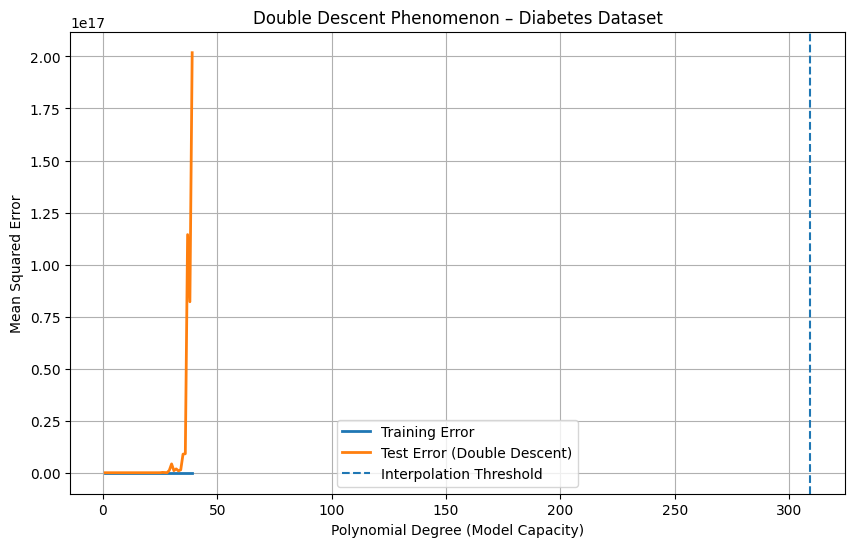

In [4]:
plt.figure(figsize=(10, 6))

plt.plot(degrees, train_errors, label="Training Error", linewidth=2)
plt.plot(degrees, test_errors, label="Test Error (Double Descent)", linewidth=2)

plt.axvline(x=X_train.shape[0], linestyle="--", label="Interpolation Threshold")

plt.xlabel("Polynomial Degree (Model Capacity)")
plt.ylabel("Mean Squared Error")
plt.title("Double Descent Phenomenon – Diabetes Dataset")

plt.legend()
plt.grid(True)
plt.show()


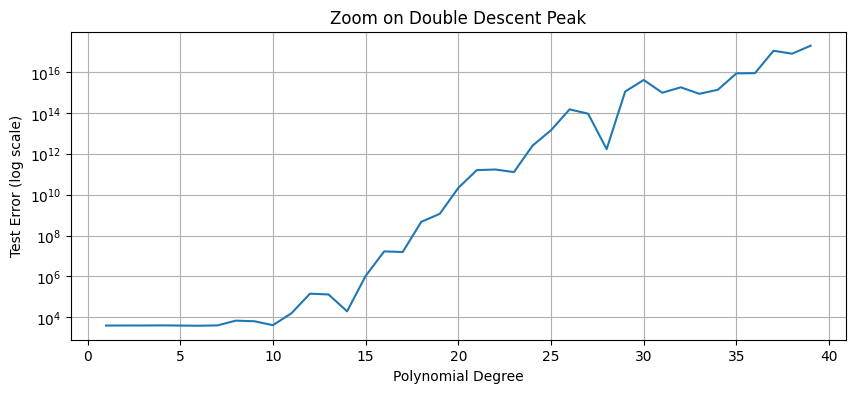

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(degrees, test_errors)
plt.yscale("log")
plt.xlabel("Polynomial Degree")
plt.ylabel("Test Error (log scale)")
plt.title("Zoom on Double Descent Peak")
plt.grid(True)
plt.show()


# A better example

Interactive Double Descent demo — run the widget below and then use the Degree slider.
Tips: use Synthetic dataset, n_train between 10 and 40, max_degree 150..300, enable log scale for clarity.


### Dataset: **Synthetic** — training samples = 30, degrees 1..200

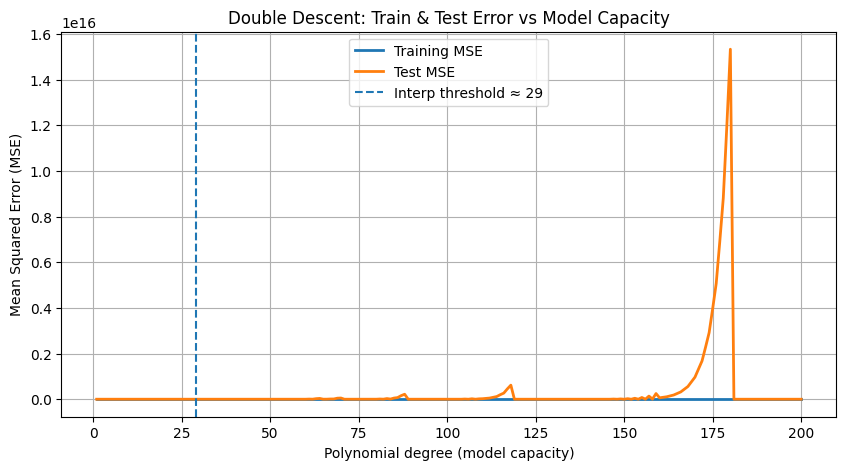

IntSlider(value=5, description='Degree', max=200, min=1)

interactive(children=(IntSlider(value=5, description='Degree', max=200, min=1), Output()), _dom_classes=('widg…

In [6]:
# Interactive Double Descent demo for Google Colab
# Copy-paste this entire cell into Colab and run.
# If the interactive widget doesn't show, run: !pip install -q ipywidgets  then restart runtime.

import sys, subprocess, importlib
import numpy as np
import matplotlib.pyplot as plt

# ensure ipywidgets
def ensure_package(pkg_name):
    try:
        return importlib.import_module(pkg_name)
    except Exception:
        print(f"Installing missing package: {pkg_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])
        return importlib.import_module(pkg_name)

ensure_package("ipywidgets")

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

from ipywidgets import interact, IntSlider, Dropdown, Checkbox, IntText, fixed
from IPython.display import display, Markdown

# -------------------------
# Data creators
# -------------------------
def make_synthetic(n_train=30, n_test=200, noise_std=0.3, random_state=42):
    rng = np.random.RandomState(random_state)
    X_all = rng.uniform(-3, 3, size=(n_test + n_train, 1))
    X_all = np.sort(X_all, axis=0)
    y_true = np.sin(X_all).ravel()
    noise = rng.normal(scale=noise_std, size=y_true.shape)
    train_idx = np.linspace(0, n_test+n_train-1, n_train, dtype=int)
    y = y_true.copy()
    y[train_idx] = y_true[train_idx] + noise[train_idx]
    X_train = X_all[train_idx]
    y_train = y[train_idx]
    mask = np.ones(X_all.shape[0], dtype=bool)
    mask[train_idx] = False
    X_test = X_all[mask]
    y_test = y_true[mask]   # use true noiseless function for a clean measure of generalization
    return X_train, X_test, y_train, y_test

def make_diabetes_single_feature(n_train=30, n_test=200, random_state=42):
    X, y = load_diabetes(return_X_y=True)
    X = X[:, 2:3]  # pick BMI feature
    X_train, X_rest, y_train, y_rest = train_test_split(X, y, train_size=n_train, random_state=random_state)
    rng = np.random.RandomState(random_state+1)
    idx = rng.choice(X_rest.shape[0], size=n_test, replace=True)
    X_test = X_rest[idx]
    y_test = y_rest[idx]
    return X_train, X_test, y_train, y_test

# -------------------------
# Compute error curves
# -------------------------
def compute_errors(X_train, X_test, y_train, y_test, max_degree=200):
    degrees = np.arange(1, max_degree+1)
    train_errors = []
    test_errors = []
    for d in degrees:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=d, include_bias=True)),
            ("lr", LinearRegression())
        ])
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        train_errors.append(mean_squared_error(y_train, y_train_pred))
        test_errors.append(mean_squared_error(y_test, y_test_pred))
    return degrees, np.array(train_errors), np.array(test_errors)

# -------------------------
# Interactive UI logic
# -------------------------
def interactive_double_descent(dataset_choice="Synthetic", n_train=30, max_degree=200, show_log=False, random_state=42):
    display(Markdown(f"### Dataset: **{dataset_choice}** — training samples = {n_train}, degrees 1..{max_degree}"))
    if dataset_choice == "Synthetic":
        X_train, X_test, y_train, y_test = make_synthetic(n_train=n_train, n_test=1000, noise_std=0.25, random_state=random_state)
    else:
        X_train, X_test, y_train, y_test = make_diabetes_single_feature(n_train=n_train, n_test=1000, random_state=random_state)

    degrees, train_errors, test_errors = compute_errors(X_train, X_test, y_train, y_test, max_degree=max_degree)
    interp_degree = max(1, X_train.shape[0] - 1)  # approximate interpolation threshold

    # full error curves
    plt.figure(figsize=(10, 5))
    plt.plot(degrees, train_errors, label="Training MSE", linewidth=2)
    plt.plot(degrees, test_errors, label="Test MSE", linewidth=2)
    plt.axvline(x=interp_degree, linestyle="--", label=f"Interp threshold ≈ {interp_degree}")
    plt.xlabel("Polynomial degree (model capacity)")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.title("Double Descent: Train & Test Error vs Model Capacity")
    plt.legend()
    plt.grid(True)
    if show_log:
        plt.yscale("log")
    plt.show()

    # per-degree visualization
    def plot_for_degree(d):
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=d, include_bias=True)),
            ("lr", LinearRegression())
        ])
        model.fit(X_train, y_train)
        X_plot = np.linspace(np.min(np.vstack([X_train, X_test])), np.max(np.vstack([X_train, X_test])), 1000).reshape(-1, 1)
        y_plot = model.predict(X_plot)

        plt.figure(figsize=(8, 5))
        plt.scatter(X_train, y_train, marker='o', label="Train points")
        plt.plot(X_plot, y_plot, linewidth=2, label=f"Model (degree={d})")
        plt.xlabel("X (single feature)")
        plt.ylabel("y")
        plt.title(f"Model fit at degree = {d}")
        plt.legend()
        plt.grid(True)
        plt.show()

        idx = d - 1
        mse_train = train_errors[idx]
        mse_test = test_errors[idx]
        print(f"Degree = {d} — Training MSE: {mse_train:.6f} — Test MSE: {mse_test:.6f}")
        if d >= interp_degree:
            print("This degree is at or beyond the interpolation threshold -> model can (approximately) interpolate training data.")
        else:
            print("Below interpolation threshold -> model cannot exactly interpolate all training samples.")

    deg_slider = IntSlider(min=1, max=max_degree, step=1, value=min(5, max_degree), description='Degree')
    display(deg_slider)
    interact(plot_for_degree, d=deg_slider)

# -------------------------
# Widget to configure experiment quickly
# -------------------------
print("Interactive Double Descent demo — run the widget below and then use the Degree slider.")
print("Tips: use Synthetic dataset, n_train between 10 and 40, max_degree 150..300, enable log scale for clarity.")

interactive_double_descent(dataset_choice="Synthetic", n_train=30, max_degree=200, show_log=False)


# Another exameple

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Ensure correct shape
X = X.reshape(-1, 1)

# Fixed split (important!)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

max_degree = len(X_train)  # critical for double descent
degrees = range(1, max_degree + 1)

train_errors = []
test_errors = []

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    Xtr = poly.fit_transform(X_train)
    Xte = poly.transform(X_test)

    model = LinearRegression()  # NO regularization
    model.fit(Xtr, y_train)

    train_errors.append(
        mean_squared_error(y_train, model.predict(Xtr))
    )
    test_errors.append(
        mean_squared_error(y_test, model.predict(Xte))
    )


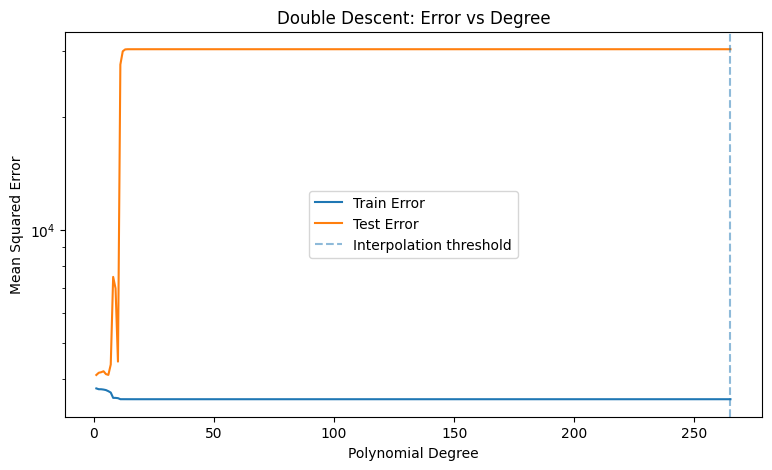

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(degrees, train_errors, label="Train Error")
plt.plot(degrees, test_errors, label="Test Error")

plt.axvline(len(X_train), linestyle="--", alpha=0.5, label="Interpolation threshold")

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.yscale("log")  # THIS IS KEY
plt.legend()
plt.title("Double Descent: Error vs Degree")
plt.show()


# Better double descent curve (hopefully)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from ipywidgets import interact, IntSlider

# -----------------------------
# 1. Synthetic dataset
# -----------------------------
np.random.seed(42)

n_samples = 25
noise_std = 0.3

X = np.random.uniform(-3, 3, size=(n_samples, 1))
y = np.sin(X).ravel() + np.random.normal(0, noise_std, size=n_samples)

# Fixed split (important!)
X_train, X_test = X[:15], X[15:]
y_train, y_test = y[:15], y[15:]

# -----------------------------
# 2. Error vs degree
# -----------------------------
def plot_double_descent(max_degree):
    degrees = range(1, max_degree + 1)
    train_errors = []
    test_errors = []

    for d in degrees:
        poly = PolynomialFeatures(degree=d, include_bias=False)
        Xtr = poly.fit_transform(X_train)
        Xte = poly.transform(X_test)

        model = LinearRegression()
        model.fit(Xtr, y_train)

        train_errors.append(
            mean_squared_error(y_train, model.predict(Xtr))
        )
        test_errors.append(
            mean_squared_error(y_test, model.predict(Xte))
        )

    plt.figure(figsize=(10, 6))
    plt.plot(degrees, train_errors, label="Training Error")
    plt.plot(degrees, test_errors, label="Test Error")

    plt.axvline(
        len(X_train),
        linestyle="--",
        label="Interpolation threshold"
    )

    plt.yscale("log")
    plt.xlabel("Polynomial Degree")
    plt.ylabel("Mean Squared Error (log scale)")
    plt.title("Double Descent: Error vs Polynomial Degree")
    plt.legend()
    plt.grid(True)
    plt.show()

# -----------------------------
# 3. Interactive slider
# -----------------------------
interact(
    plot_double_descent,
    max_degree=IntSlider(min=5, max=60, step=1, value=40)
)


interactive(children=(IntSlider(value=40, description='max_degree', max=60, min=5), Output()), _dom_classes=('…

<function __main__.plot_double_descent(max_degree)>

# Example 4

Running simulation with 20 training samples...


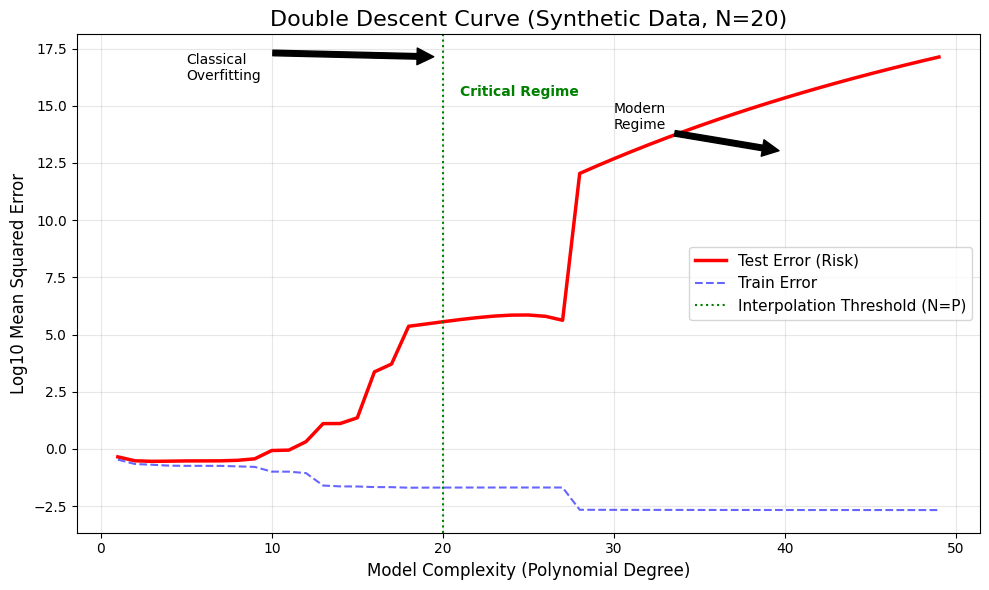

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Configuration for the Synthetic Data
np.random.seed(42)
n_train = 20        # Small training set to easily reach Overparameterization
n_test = 1000       # Large test set for stable error estimation
noise_level = 0.5   # Noise is required to see the "peak"

# 2. Generate Data (Underlying function: y = cos(1.5 * pi * x))
def true_fun(X):
    return np.cos(1.5 * np.pi * X)

# Training data
X_train = np.sort(np.random.rand(n_train))
y_train = true_fun(X_train) + np.random.randn(n_train) * noise_level

# Testing data (dense grid to approximate true error)
X_test = np.sort(np.random.rand(n_test))
y_test = true_fun(X_test) + np.random.randn(n_test) * noise_level

# Reshape for sklearn
X_train = X_train[:, np.newaxis]
X_test = X_test[:, np.newaxis]

# 3. Experiment Loop
degrees = np.arange(1, 50)
train_errors = []
test_errors = []

print(f"Running simulation with {n_train} training samples...")

for d in degrees:
    # We use standard LinearRegression. When features > samples,
    # sklearn uses a least-squares solver that approximates the
    # "minimum norm" solution, which is key for the second descent.
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(), # Scaling helps numerical stability at high degrees
        LinearRegression()
    )

    model.fit(X_train, y_train)

    # Predict
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate Log MSE (Log helps visualize the massive scale differences)
    train_errors.append(np.log10(mean_squared_error(y_train, y_train_pred)))
    test_errors.append(np.log10(mean_squared_error(y_test, y_test_pred)))

# 4. Plotting
plt.figure(figsize=(10, 6))
plt.plot(degrees, test_errors, label='Test Error (Risk)', color='red', linewidth=2.5)
plt.plot(degrees, train_errors, label='Train Error', color='blue', linestyle='--', alpha=0.6)

# Add visual marker for the interpolation threshold (N = P)
plt.axvline(x=n_train, color='green', linestyle=':', label='Interpolation Threshold (N=P)')
plt.text(n_train + 1, max(test_errors)*0.9, 'Critical Regime', color='green', fontweight='bold')

# Formatting
plt.title(f'Double Descent Curve (Synthetic Data, N={n_train})', fontsize=16)
plt.xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
plt.ylabel('Log10 Mean Squared Error', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

# Add annotations for the regimes
plt.annotate('Classical\nOverfitting', xy=(n_train, max(test_errors)), xytext=(5, max(test_errors)-1),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.annotate('Modern\nRegime', xy=(40, min(test_errors[30:])), xytext=(30, min(test_errors[30:])+1),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.tight_layout()
plt.show()

In [11]:
# Example 5

Simulating Double Descent...


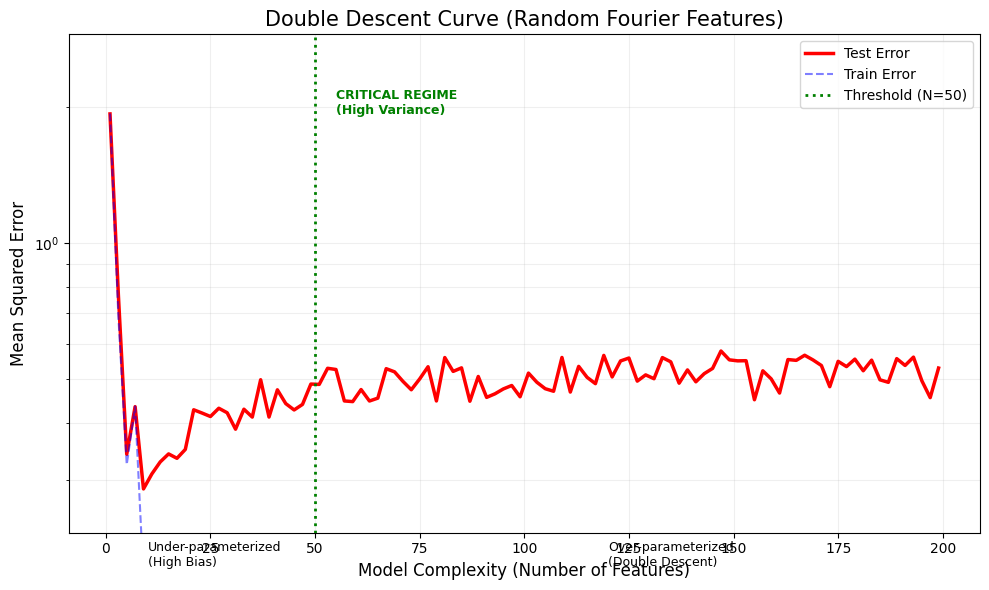

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# 1. Setup Synthetic Data
np.random.seed(42)
n_train = 50          # The "Interpolation Threshold" will be here
n_test = 500
noise = 0.5

# Function: y = x * sin(x) + noise
def get_data(n):
    X = np.random.uniform(-4, 4, size=(n, 1))
    y = (X * np.sin(X)).flatten() + np.random.normal(0, noise, n)
    return X, y

X_train, y_train = get_data(n_train)
X_test, y_test = get_data(n_test)

# 2. Experiment: Vary the Number of Random Features (Complexity)
# We go from 1 feature up to 4*n_train (well into over-parameterization)
n_features_list = np.arange(1, 200, 2)
train_mse = []
test_mse = []

print("Simulating Double Descent...")

for D in n_features_list:
    # RBFSampler creates 'D' random features (simulating a D-width neural net)
    # gamma=1.0 controls the "frequency" of the features
    rff = RBFSampler(n_components=D, gamma=1.0, random_state=123)
    X_train_rff = rff.fit_transform(X_train)
    X_test_rff = rff.transform(X_test)

    # We use Ridge with a tiny alpha.
    # alpha -> 0 approximates the "Minimum Norm Solution" required for double descent.
    model = Ridge(alpha=1e-5, fit_intercept=False)
    model.fit(X_train_rff, y_train)

    # Measure Error
    train_mse.append(mean_squared_error(y_train, model.predict(X_train_rff)))
    test_mse.append(mean_squared_error(y_test, model.predict(X_test_rff)))

# 3. Plotting
plt.figure(figsize=(10, 6))

# Plot Test Error (The Double Descent)
plt.plot(n_features_list, test_mse, label='Test Error', color='red', linewidth=2.5)
# Plot Train Error (Goes to zero)
plt.plot(n_features_list, train_mse, label='Train Error', color='blue', linestyle='--', alpha=0.5)

# The Interpolation Threshold Line
plt.axvline(x=n_train, color='green', linestyle=':', linewidth=2, label=f'Threshold (N={n_train})')

# Annotations to make your explanation easy
plt.title('Double Descent Curve (Random Fourier Features)', fontsize=15)
plt.xlabel('Model Complexity (Number of Features)', fontsize=12)
plt.ylabel('Mean Squared Error', fontsize=12)
plt.yscale('log') # Log scale is crucial to see the descent clearly!
plt.ylim(min(test_mse)*0.8, max(test_mse)*1.5)

# Add text for the regimes
peak_y = max(test_mse)
plt.text(10, peak_y/10, "Under-parameterized\n(High Bias)", fontsize=9, color='black')
plt.text(n_train+5, peak_y, "CRITICAL REGIME\n(High Variance)", fontsize=9, color='green', fontweight='bold')
plt.text(120, peak_y/10, "Over-parameterized\n(Double Descent)", fontsize=9, color='black')

plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.tight_layout()
plt.show()

In [13]:
# Example 6

Simulating 50 trials. This may take a minute...


100%|██████████| 50/50 [00:52<00:00,  1.05s/it]
/tmp/ipython-input-1815142394.py:96: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


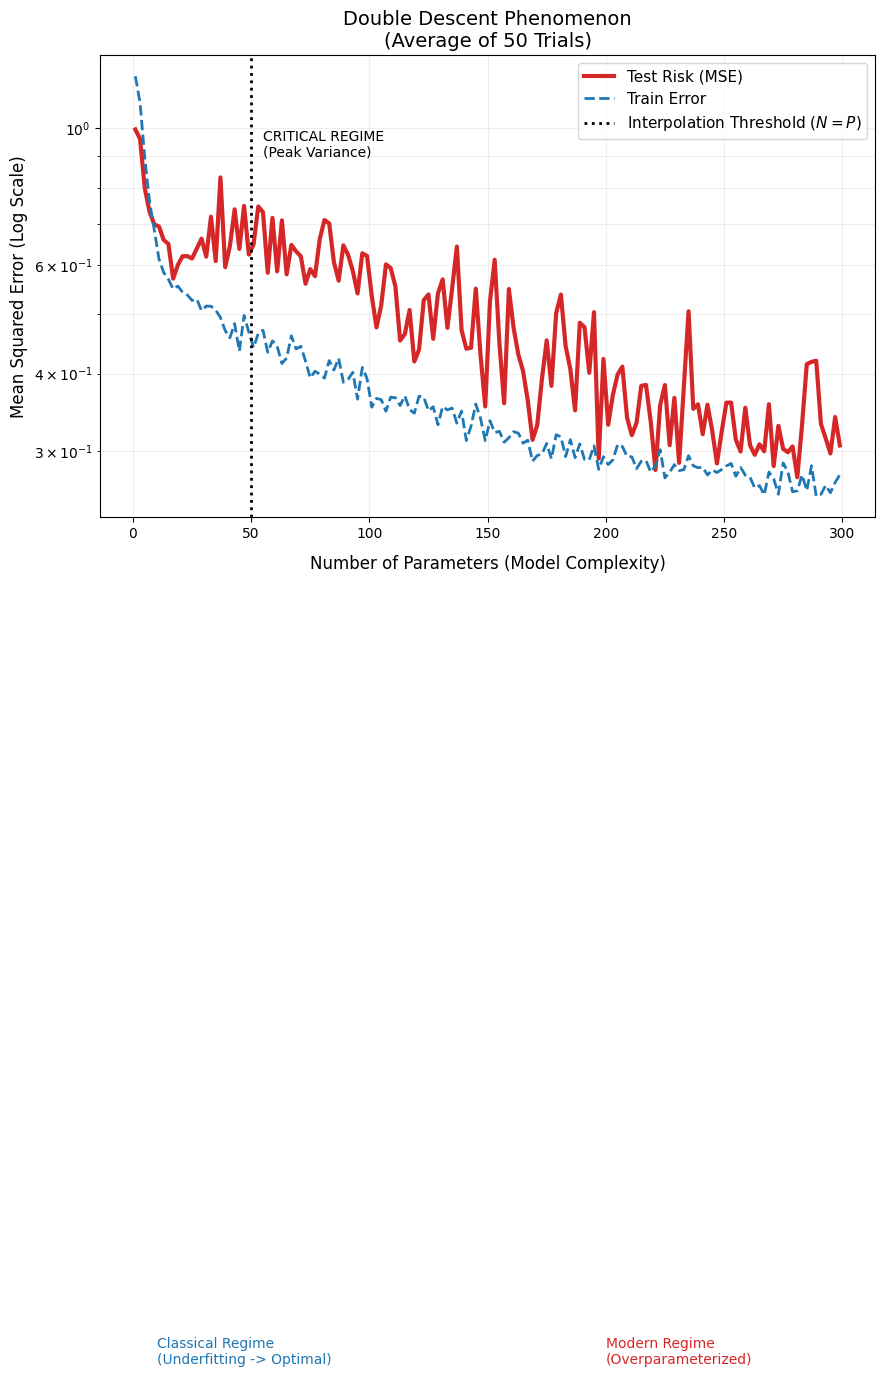

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from tqdm import tqdm # Progress bar

# --- CONFIGURATION ---
N_TRAIN = 50           # Number of training points
N_TEST = 1000          # Large test set for accuracy
NOISE_STD = 0.5        # Label noise
N_TRIALS = 50          # Averaging over 50 runs creates the smooth curve
MAX_FEATURES = 300     # How complex the model gets
LAMBDA = 1e-4          # Tiny regularization (effectively unregularized/minimum norm)

# True function: A simple non-linear wave
def true_function(x):
    return np.sin(3 * x) + np.sin(5 * x)

# --- EXPERIMENT LOOP ---
# We track error for every model size from 1 to MAX_FEATURES
model_sizes = np.arange(1, MAX_FEATURES, 2)
avg_train_err = np.zeros(len(model_sizes))
avg_test_err = np.zeros(len(model_sizes))

print(f"Simulating {N_TRIALS} trials. This may take a minute...")

for trial in tqdm(range(N_TRIALS)):
    # 1. Generate Fresh Data for this trial
    X_train = np.random.uniform(-np.pi, np.pi, (N_TRAIN, 1))
    y_train = true_function(X_train).ravel() + np.random.normal(0, NOISE_STD, N_TRAIN)

    X_test = np.random.uniform(-np.pi, np.pi, (N_TEST, 1))
    y_test = true_function(X_test).ravel() # Test set has no noise (we want true risk)

    # 2. Iterate through model complexities
    trial_train_err = []
    trial_test_err = []

    for D in model_sizes:
        # Create D random features (Approximates a Neural Net of width D)
        # We use a fixed random state per feature-size WITHIN a trial to be consistent,
        # but the data changes every trial.
        rff = RBFSampler(n_components=D, gamma=1.0)

        X_train_trans = rff.fit_transform(X_train)
        X_test_trans = rff.transform(X_test)

        # Fit Model
        # We use Ridge with tiny lambda. This approximates the Moore-Penrose
        # Pseudo-inverse, which chooses the "minimum norm" solution.
        model = Ridge(alpha=LAMBDA, fit_intercept=False)
        model.fit(X_train_trans, y_train)

        # Record Errors
        y_pred_train = model.predict(X_train_trans)
        y_pred_test = model.predict(X_test_trans)

        trial_train_err.append(mean_squared_error(y_train, y_pred_train))
        trial_test_err.append(mean_squared_error(y_test, y_pred_test))

    # Accumulate results
    avg_train_err += np.array(trial_train_err)
    avg_test_err += np.array(trial_test_err)

# Average out
avg_train_err /= N_TRIALS
avg_test_err /= N_TRIALS

# --- PLOTTING ---
plt.figure(figsize=(10, 6), dpi=100)

# 1. Plot Test Error (The curve you want)
plt.plot(model_sizes, avg_test_err, color='#d62728', linewidth=3, label='Test Risk (MSE)')

# 2. Plot Train Error
plt.plot(model_sizes, avg_train_err, color='#1f77b4', linewidth=2, linestyle='--', label='Train Error')

# 3. The Interpolation Threshold
plt.axvline(x=N_TRAIN, color='black', linestyle=':', linewidth=2, label='Interpolation Threshold ($N=P$)')

# Styling to look like a paper
plt.yscale('log')
plt.xlabel('Number of Parameters (Model Complexity)', fontsize=12, labelpad=10)
plt.ylabel('Mean Squared Error (Log Scale)', fontsize=12)
plt.title(f'Double Descent Phenomenon\n(Average of {N_TRIALS} Trials)', fontsize=14)
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.legend(fontsize=11)

# Annotations
peak_val = np.max(avg_test_err)
plt.text(N_TRAIN+5, peak_val, 'CRITICAL REGIME\n(Peak Variance)', color='black', fontsize=10, verticalalignment='top')
plt.text(10, peak_val/100, 'Classical Regime\n(Underfitting -> Optimal)', color='#1f77b4', fontsize=10)
plt.text(200, peak_val/100, 'Modern Regime\n(Overparameterized)', color='#d62728', fontsize=10)

plt.tight_layout()
plt.show()